# 05b · Red del conectoma GFS: signo, máscara y estructura

Etapa 5, parte local (no necesita token). Toma lo que descargó `05a_conectoma_descarga_colab.ipynb` y prepara la red de la fase 2 (Opción A, revisión §12): **W = signo ⊙ softplus(θ) ⊙ máscara**.

- **Máscara:** hay conexión de la neurona *j* a la *i* si neuPrint cuenta al menos una sinapsis química.
- **Signo:** sale del neurotransmisor de la neurona presináptica (`src/modelo_fly/conectoma.py`).
- **Conteo sináptico:** sirve para inicializar θ y para la Opción B (pesos fijos).

**Entradas:** `data/processed/hito3/gfs_nodes.csv`, `gfs_edges.csv`, `gfs_meta.json`.
**Salidas:** `data/processed/hito3/gfs_neuronas.csv` (327 neuronas en el orden de la red, con su signo), `gfs_conexiones.csv` (aristas con índices y signo) y la figura `results/hito3/fig_conectoma_tipos.png`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró data/raw. Abre el notebook dentro del repositorio.")
sys.path.insert(0, str(ROOT / "src"))

from modelo_fly.conectoma import CONF_MIN, SALIDA_DLMN, SALIDA_TTMN, TIPOS, matrices, neuronas

PROC = ROOT / "data" / "processed" / "hito3"
RES = ROOT / "results" / "hito3"
nodes = pd.read_csv(PROC / "gfs_nodes.csv")
edges = pd.read_csv(PROC / "gfs_edges.csv")
meta = json.loads((PROC / "gfs_meta.json").read_text(encoding="utf-8"))
print(meta["dataset"], "| descargado", meta["fecha_descarga"], "| neuprint-python", meta["neuprint_python"])

male-cns:v1.0 | descargado 2026-11-05T18:06:54+00:00 | neuprint-python 0.6.4


## 1. ¿Es el mismo subgrafo del Hito 2?

El Hito 2 (`notebooks/hito2/03_conectoma_neuprint.ipynb`) tenía 327 neuronas y 20 684 aristas. En el Colab se comprobó además que el peso total de cada par coincide con la suma por ROI que usaba el Hito 2 (0 pares distintos).

In [2]:
print("Neuronas:", len(nodes), "| conexiones (pares pre→post):", len(edges), "| sinapsis:", int(edges["weight"].sum()))
assert len(nodes) == 327 and len(edges) == 20684
assert set(edges["bodyId_pre"]) | set(edges["bodyId_post"]) <= set(nodes["bodyId"])
assert not edges.duplicated(["bodyId_pre", "bodyId_post"]).any()
print("Autoconexiones:", int((edges["bodyId_pre"] == edges["bodyId_post"]).sum()))
display(nodes.groupby(["capa", "type"]).size().rename("neuronas").to_frame())

Neuronas: 327 | conexiones (pares pre→post): 20684 | sinapsis: 79950
Autoconexiones: 0


neuronas
capa     type               
decision DNp01             2
         PSI               2
entrada  LC4             126
         LPLC2           185
salida   DLMn a, b         2
         DLMn c-f          8
         TTMn              2

## 2. Neurotransmisor y signo

Orden de decisión: `consensusNt` → `celltypePredictedNt` si su confianza es ≥ 0.5 → literatura para el tipo. Acetilcolina = +1; glutamato, GABA e histamina = −1.

In [3]:
tabla = neuronas(nodes)
resumen = (tabla.groupby("type", sort=False)
           .agg(neuronas=("idx", "size"), predictedNt=("predictedNt", lambda s: s.value_counts().to_dict()),
                consensusNt=("consensusNt", "first"), celltypePredictedNt=("celltypePredictedNt", "first"),
                confianza_tipo=("celltypePredictedNtConfidence", "first"),
                nt_final=("nt", "first"), origen=("origen_nt", "first"), signo=("signo", "first"))
           .round(2))
display(resumen)
print("Neuronas por origen del neurotransmisor:", tabla["origen_nt"].value_counts().to_dict())

,neuronas,predictedNt,consensusNt,celltypePredictedNt,confianza_tipo,nt_final,origen,signo
type,,,,,,,,
LC4,126,{'acetylcholine': 126},acetylcholine,acetylcholine,0.96,acetylcholine,consenso,1
LPLC2,185,{'acetylcholine': 185},acetylcholine,acetylcholine,0.95,acetylcholine,consenso,1
DNp01,2,{'acetylcholine': 2},acetylcholine,acetylcholine,0.53,acetylcholine,consenso,1
PSI,2,{'unclear': 2},unclear,unclear,0.37,acetylcholine,literatura,1
TTMn,2,"{'unclear': 1, 'histamine': 1}",glutamate,histamine,0.52,glutamate,consenso,-1
"DLMn a, b",2,"{'unclear': 1, 'acetylcholine': 1}",unclear,unclear,0.38,glutamate,literatura,-1
DLMn c-f,8,"{'unclear': 7, 'acetylcholine': 1}",unclear,unclear,0.45,glutamate,literatura,-1


Neuronas por origen del neurotransmisor: {'consenso': 315, 'literatura': 12}


In [4]:
conteo, mascara, con_signo = matrices(tabla, edges)
signo_pre = tabla.set_index("bodyId")["signo"]
edges["signo"] = edges["bodyId_pre"].map(signo_pre)
print("Densidad de la máscara:", f"{mascara.mean():.1%}", f"({mascara.sum()} de {mascara.size})")
print("Conexiones inhibidoras:", int((edges['signo'] < 0).sum()), "de", len(edges),
      f"({(edges['signo'] < 0).mean():.2%})")
print("Sinapsis inhibidoras:", int(edges.loc[edges['signo'] < 0, 'weight'].sum()), "de", int(edges['weight'].sum()),
      f"({edges.loc[edges['signo'] < 0, 'weight'].sum() / edges['weight'].sum():.2%})")
display(edges[edges["signo"] < 0].groupby(["type_pre", "type_post"])["weight"].agg(["count", "sum"]))

Densidad de la máscara: 19.3% (20684 de 106929)
Conexiones inhibidoras: 55 de 20684 (0.27%)
Sinapsis inhibidoras: 166 de 79950 (0.21%)


count  sum
type_pre  type_post            
DLMn a, b DLMn a, b      2    6
          DLMn c-f       8   18
          PSI            2   15
DLMn c-f  DLMn a, b      8   21
          DLMn c-f      26   90
          PSI            7   13
TTMn      DNp01          2    3

## 3. Estructura: ¿por dónde pasa la señal?

La entrada del modelo (atributos del outfit) llega a `LC4` y `LPLC2`; las salidas se leen en `TTMn` (real/falso) y `DLMn` (armonía).

In [5]:
por_tipo = (edges.groupby(["type_pre", "type_post"])["weight"].sum().unstack(fill_value=0)
            .reindex(index=TIPOS, columns=TIPOS, fill_value=0))
total = por_tipo.to_numpy().sum()
entrada = ["LC4", "LPLC2"]
print("Sinapsis dentro de la capa de entrada:", f"{por_tipo.loc[entrada, entrada].to_numpy().sum() / total:.1%}")
print("Sinapsis de la entrada hacia DNp01:", int(por_tipo.loc[entrada, "DNp01"].sum()))
print("Neuronas de entrada conectadas directo a DNp01:",
      edges.loc[edges["type_pre"].isin(entrada) & (edges["type_post"] == "DNp01"), "bodyId_pre"].nunique(),
      "de", int(tabla["type"].isin(entrada).sum()))
for pre, post in [("DNp01", "TTMn"), ("DNp01", "PSI"), ("PSI", "DLMn a, b"), ("PSI", "DLMn c-f")]:
    d = edges[(edges["type_pre"] == pre) & (edges["type_post"] == post)]
    print(f"  {pre} → {post}: {len(d)} conexiones, {int(d['weight'].sum())} sinapsis")

G = nx.DiGraph()
G.add_edges_from(zip(edges["bodyId_pre"], edges["bodyId_post"]))
tipo_de = dict(zip(tabla["bodyId"], tabla["type"]))
ids_entrada = [b for b, t in tipo_de.items() if t in entrada]
for nombre, tipos in [("TTMn", SALIDA_TTMN), ("DLMn", SALIDA_DLMN)]:
    destinos = [b for b, t in tipo_de.items() if t in tipos]
    largo = nx.multi_source_dijkstra_path_length(G, ids_entrada)
    print(f"Camino más corto de la entrada a {nombre}:", sorted({largo.get(d) for d in destinos}), "saltos")

Sinapsis dentro de la capa de entrada: 84.8%
Sinapsis de la entrada hacia DNp01: 11224
Neuronas de entrada conectadas directo a DNp01: 311 de 311
  DNp01 → TTMn: 2 conexiones, 90 sinapsis
  DNp01 → PSI: 4 conexiones, 16 sinapsis
  PSI → DLMn a, b: 2 conexiones, 43 sinapsis
  PSI → DLMn c-f: 8 conexiones, 406 sinapsis
Camino más corto de la entrada a TTMn: [2] saltos
Camino más corto de la entrada a DLMn: [3] saltos


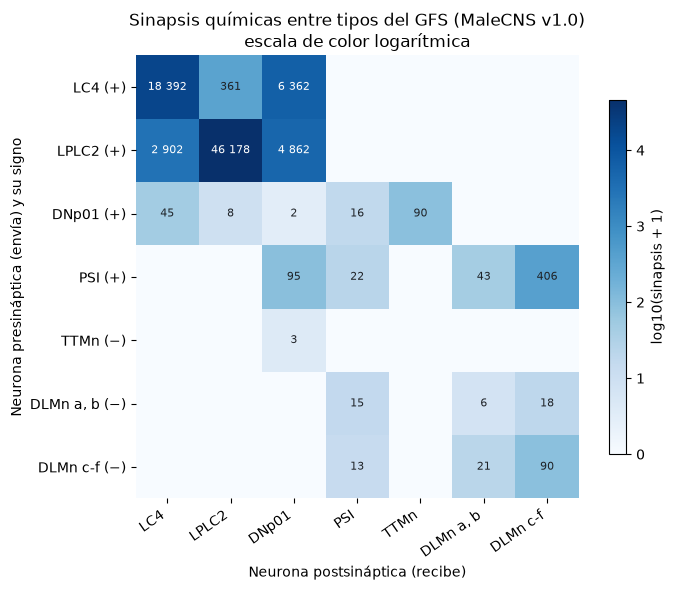

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 6))
valores = np.log10(por_tipo.to_numpy() + 1)
im = ax.imshow(valores, cmap="Blues")
ax.set_xticks(range(len(TIPOS)), TIPOS, rotation=35, ha="right")
ax.set_yticks(range(len(TIPOS)), [f"{t} ({'−' if signo_pre[tabla.loc[tabla['type'] == t, 'bodyId'].iloc[0]] < 0 else '+'})"
                                   for t in TIPOS])
for i in range(len(TIPOS)):
    for j in range(len(TIPOS)):
        v = int(por_tipo.iat[i, j])
        if v:
            ax.text(j, i, f"{v:,}".replace(",", " "), ha="center", va="center", fontsize=8,
                    color="white" if valores[i, j] > valores.max() * 0.6 else "#1f2328")
ax.set_xlabel("Neurona postsináptica (recibe)")
ax.set_ylabel("Neurona presináptica (envía) y su signo")
ax.set_title("Sinapsis químicas entre tipos del GFS (MaleCNS v1.0)\nescala de color logarítmica")
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="log10(sinapsis + 1)")
fig.tight_layout()
RES.mkdir(parents=True, exist_ok=True)
fig.savefig(RES / "fig_conectoma_tipos.png", dpi=150)
plt.show()

## 4. Salidas

In [7]:
tabla.to_csv(PROC / "gfs_neuronas.csv", index=False, encoding="utf-8")
idx = dict(zip(tabla["bodyId"], tabla["idx"]))
conexiones = edges.assign(idx_pre=edges["bodyId_pre"].map(idx), idx_post=edges["bodyId_post"].map(idx))
conexiones = conexiones[["idx_pre", "idx_post", "bodyId_pre", "bodyId_post", "type_pre", "type_post",
                         "weight", "signo"]].sort_values(["idx_post", "idx_pre"])
conexiones.to_csv(PROC / "gfs_conexiones.csv", index=False, encoding="utf-8")
print("Guardado: gfs_neuronas.csv", tabla.shape, "| gfs_conexiones.csv", conexiones.shape)

Guardado: gfs_neuronas.csv (327, 12) | gfs_conexiones.csv (20684, 8)
